# Previsão de um ano, como em produção

A série já está em `dados/internacoes_mes_uf.parquet`. Este notebook não baixa arquivo do DATASUS.

O ensaio imita o modelo no dia em que ele seria colocado para prever. A data de corte é 31 de dezembro de 2024. Nesse dia, 2025 ainda não aconteceu. O treino usa só o que já existia até dezembro de 2024. A previsão pede os doze meses seguintes, janeiro a dezembro de 2025. A linha azul desse ano é o que de fato ocorreu, e nenhum desses doze valores entra no ajuste.

2026 não serve para esse ensaio. Agosto e setembro ainda estão incompletos, então não há um ano fechado para confrontar a previsão.

A linha cinza do gráfico é o histórico que o treino viu. A linha azul é só 2025, fora do treino. Laranja é o Temporal Fusion Transformer, verde é a LSTM, e a tracejada repete o mesmo mês de 2024, que era a informação sazonal disponível na data de corte.

## 1. Separar o que já se sabia do que ainda não tinha acontecido

Cada ponto é o número de AIHs normais com data de internação naquele mês, no estado do hospital.

O painel começa em julho de 2008. Os arquivos existem desde janeiro, mas os primeiros meses ainda perdem internações faturadas em 2007. `treino` acaba em dezembro de 2024. `teste` é o ano de 2025, doze meses. Nada de 2025 é usado para estimar média, desvio ou peso da rede.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from lightning.pytorch import Trainer
from pytorch_forecasting import TemporalFusionTransformer, TimeSeriesDataSet
from pytorch_forecasting.data import GroupNormalizer
from pytorch_forecasting.metrics import QuantileLoss
from torch import nn

from datasus import UFS

PASTA = Path("dados")
JANELA = 24
HORIZONTE = 12
SEMENTE = 42

torch.manual_seed(SEMENTE)
np.random.seed(SEMENTE)

serie = pd.read_parquet(PASTA / "internacoes_mes_uf.parquet")
painel = serie.pivot(index="mes", columns="uf", values="internacoes")
painel = painel.reindex(columns=list(UFS))
painel = painel.reindex(pd.date_range("2008-07-01", "2025-12-01", freq="MS"))

treino = painel.loc[:"2024-12-01"]
teste = painel.loc["2025-01-01":"2025-12-01"]
print(f"Visto no treino: {treino.index.min():%Y-%m} a {treino.index.max():%Y-%m} ({len(treino)} meses)")
print(f"Fora do treino:  {teste.index.min():%Y-%m} a {teste.index.max():%Y-%m} ({len(teste)} meses)")
print(f"Valores ausentes em 2025: {int(teste.isna().sum().sum())}")


Visto no treino: 2008-07 a 2024-12 (198 meses)
Fora do treino:  2025-01 a 2025-12 (12 meses)
Valores ausentes em 2025: 0


C:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\pytorch_forecasting\models\base\_base_model.py:30: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


## 2. A LSTM, ajustada só até dezembro de 2024

A escala de cada estado usa média e desvio de julho de 2008 a dezembro de 2024. 2025 não entra nessa conta.

Uma janela lê 24 meses e responde os 12 seguintes. Para o mês de destino, a rede já conhece o mesmo mês do ano anterior e o seno e o cosseno do calendário. A previsão é esse valor do ano anterior mais uma correção. A camada que produz a correção começa em zero: na primeira época, a previsão é repetir o ano anterior.

Só entra no treino a janela cuja resposta termina até dezembro de 2024. A janela de teste começa em janeiro de 2025. O passado dela é 2023 e 2024. Os doze alvos são 2025, que a perda nunca viu.

In [2]:
class EscalaEstado:
    def __init__(self, base: pd.DataFrame):
        self.media = base.mean()
        self.desvio = base.std().clip(lower=1)

    def aplicar(self, valores: pd.DataFrame) -> pd.DataFrame:
        return (valores - self.media) / self.desvio

    def desfazer(self, uf: str, valores: np.ndarray) -> np.ndarray:
        return valores * float(self.desvio[uf]) + float(self.media[uf])


def calendario(indice: pd.DatetimeIndex) -> np.ndarray:
    angulo = 2 * np.pi * indice.month.to_numpy() / 12
    return np.column_stack([np.sin(angulo), np.cos(angulo)]).astype(np.float32)


def montar_janelas(escalado: pd.DataFrame, t_inicial: int, t_final: int):
    cal = calendario(escalado.index)
    matriz = escalado.to_numpy(dtype=np.float32)
    passados, futuros, saidas, estados = [], [], [], []
    for coluna, uf in enumerate(escalado.columns):
        serie_uf = matriz[:, coluna]
        for t in range(t_inicial, t_final + 1):
            quantidade = serie_uf[t - JANELA : t][:, None]
            passados.append(np.hstack([quantidade, cal[t - JANELA : t]]))
            meses = np.arange(t, t + HORIZONTE)
            sazonal = serie_uf[meses - 12][:, None]
            futuros.append(np.hstack([sazonal, cal[meses]]))
            saidas.append(serie_uf[meses])
            estados.append(uf)
    passado = torch.tensor(np.stack(passados), dtype=torch.float32)
    futuro = torch.tensor(np.stack(futuros), dtype=torch.float32)
    y = torch.tensor(np.stack(saidas), dtype=torch.float32)
    return passado, futuro, y, estados


class LSTMInternacoes(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=3, hidden_size=64, batch_first=True)
        self.variacao = nn.Linear(64 + 3, 1)
        nn.init.zeros_(self.variacao.weight)
        nn.init.zeros_(self.variacao.bias)

    def forward(self, passado, futuro):
        sequencia, _ = self.lstm(passado)
        estado = sequencia[:, -1, :].unsqueeze(1).expand(-1, futuro.shape[1], -1)
        delta = self.variacao(torch.cat([estado, futuro], dim=-1)).squeeze(-1)
        return futuro[:, :, 0] + delta


def treinar_lstm(passado, futuro, y, epocas=80, lote=128):
    modelo = LSTMInternacoes()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    perda = nn.MSELoss()
    gerador = torch.Generator().manual_seed(SEMENTE)
    modelo.train()
    for epoca in range(1, epocas + 1):
        ordem = torch.randperm(len(passado), generator=gerador)
        total = 0.0
        for inicio in range(0, len(passado), lote):
            indice = ordem[inicio : inicio + lote]
            otimizador.zero_grad()
            erro = perda(modelo(passado[indice], futuro[indice]), y[indice])
            erro.backward()
            otimizador.step()
            total += erro.item() * len(indice)
        if epoca == 1 or epoca % 20 == 0:
            print(f"LSTM época {epoca:02d}  erro {total / len(passado):.5f}")
    modelo.eval()
    return modelo


escala = EscalaEstado(treino)
escalado = escala.aplicar(painel)
inicio_teste = len(treino)
p_treino, f_treino, y_treino, _ = montar_janelas(escalado, JANELA, inicio_teste - HORIZONTE)
p_teste, f_teste, _, ufs_teste = montar_janelas(escalado, inicio_teste, inicio_teste)
print(f"Janelas de treino da LSTM: {len(p_treino):,}. Estados no teste: {len(p_teste)}.")

lstm_modelo = treinar_lstm(p_treino, f_treino, y_treino)
with torch.no_grad():
    lstm_escala = lstm_modelo(p_teste, f_teste).numpy()

lstm = pd.DataFrame(index=teste.index, columns=list(UFS), dtype=float)
for i, uf in enumerate(ufs_teste):
    lstm[uf] = np.clip(escala.desfazer(uf, lstm_escala[i]), 0, None)


Janelas de treino da LSTM: 4,401. Estados no teste: 27.


LSTM época 01  erro 0.66692

LSTM época 20  erro 0.42737


LSTM época 40  erro 0.38018


LSTM época 60  erro 0.33363


LSTM época 80  erro 0.30229


## 3. O Temporal Fusion Transformer, no mesmo corte

A tabela longa tem uma linha por estado e por mês. `mesmo_mes_ano_anterior` é a quantidade de doze meses antes. Os doze primeiros meses não têm esse valor e saem da tabela, então o TFT começa em julho de 2009. O teste continua sendo 2025.

O conjunto de treino recebe apenas linhas até dezembro de 2024. A janela de teste é a última de cada estado numa série que acaba em dezembro de 2025: doze meses, que são exatamente o ano de 2025. O passado dessa janela é 2023 e 2024.

O TFT resume os 24 meses numa LSTM, pesa esses meses com atenção e recebe, no futuro, o calendário e o mesmo mês de 2024. A perda é de quantis. O número comparado é a mediana. São 25 épocas, sem validação no meio do caminho, para o critério de parada não espiar 2025.

In [3]:
longo = painel.stack().rename("internacoes").reset_index()
longo.columns = ["mes", "uf", "internacoes"]
longo = longo.sort_values(["uf", "mes"])
longo["mesmo_mes_ano_anterior"] = longo.groupby("uf")["internacoes"].shift(12)
longo = longo.dropna().reset_index(drop=True)
longo["time_idx"] = longo.groupby("uf").cumcount()
angulo = 2 * np.pi * longo["mes"].dt.month / 12
longo["mes_sin"] = np.sin(angulo)
longo["mes_cos"] = np.cos(angulo)
corte = int(longo.loc[longo["mes"] == "2024-12-01", "time_idx"].iloc[0])

conjunto_treino = TimeSeriesDataSet(
    longo[longo.time_idx <= corte],
    time_idx="time_idx",
    target="internacoes",
    group_ids=["uf"],
    max_encoder_length=JANELA,
    min_encoder_length=JANELA,
    max_prediction_length=HORIZONTE,
    min_prediction_length=HORIZONTE,
    time_varying_known_reals=["mes_sin", "mes_cos", "mesmo_mes_ano_anterior"],
    time_varying_unknown_reals=["internacoes"],
    target_normalizer=GroupNormalizer(groups=["uf"]),
    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True,
    randomize_length=False,
)
conjunto_teste = TimeSeriesDataSet.from_dataset(
    conjunto_treino, longo, predict=True, stop_randomization=True
)
print(f"Janelas de treino do TFT: {len(conjunto_treino):,}. Janelas de teste: {len(conjunto_teste)}.")

tft_modelo = TemporalFusionTransformer.from_dataset(
    conjunto_treino,
    learning_rate=1e-3,
    hidden_size=32,
    attention_head_size=1,
    dropout=0.1,
    hidden_continuous_size=16,
    loss=QuantileLoss(),
)
Trainer(
    max_epochs=25,
    accelerator="cpu",
    gradient_clip_val=0.1,
    enable_model_summary=False,
    logger=False,
    enable_checkpointing=False,
    enable_progress_bar=True,
    num_sanity_val_steps=0,
).fit(
    tft_modelo,
    train_dataloaders=conjunto_treino.to_dataloader(train=True, batch_size=64, num_workers=0),
)
saida = tft_modelo.predict(
    conjunto_teste.to_dataloader(train=False, batch_size=64, num_workers=0),
    mode="prediction",
    return_index=True,
    trainer_kwargs={"logger": False, "enable_progress_bar": False},
)
valores = saida.output.detach().numpy()
tft = pd.DataFrame(index=teste.index, columns=list(UFS), dtype=float)
for i, uf in enumerate(saida.index["uf"]):
    tft[uf] = np.clip(valores[i], 0, None)


C:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
C:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.
GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Janelas de treino do TFT: 4,077. Janelas de teste: 27.


C:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\lightning\pytorch\trainer\configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.


C:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\rich\live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

... (4 outputs left out)

TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


C:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


## 4. Comparar com o que aconteceu em 2025

As três previsões foram feitas só com informação disponível em dezembro de 2024. A referência sem modelo repete o mesmo mês de 2024.

O MAE é a média do módulo da diferença, em internações por mês. O MAPE divide essa diferença pelo observado de 2025. Os dois são calculados em cada estado e depois resumidos pela média dos 27. Quanto menor, mais perto a previsão ficou da linha azul, que o treino não viu.

In [4]:
referencia = painel.shift(12).loc[teste.index]
lstm.to_parquet(PASTA / "producao_2025_lstm.parquet")
tft.to_parquet(PASTA / "producao_2025_tft.parquet")


def erro_por_estado(real: pd.DataFrame, estimativa: pd.DataFrame) -> pd.DataFrame:
    linhas = []
    for uf in real.columns:
        pares = pd.DataFrame({"real": real[uf], "est": estimativa[uf]}).dropna()
        diferenca = (pares["est"] - pares["real"]).abs()
        linhas.append(
            {
                "uf": uf,
                "mae": diferenca.mean(),
                "mape_%": (diferenca / pares["real"].clip(lower=1)).mean() * 100,
            }
        )
    return pd.DataFrame(linhas).set_index("uf")


comparacao = pd.concat(
    {
        "tft": erro_por_estado(teste, tft),
        "lstm": erro_por_estado(teste, lstm),
        "mesmo_mes_2024": erro_por_estado(teste, referencia),
    },
    axis=1,
)
print("Erro médio entre os estados, ano de 2025, fora do treino")
print(comparacao.mean().round(1).to_string())
comparacao.round(1)


Erro médio entre os estados, ano de 2025, fora do treino
tft             mae       1584.8
                mape_%       4.5
lstm            mae       2752.2
                mape_%       6.9
mesmo_mes_2024  mae       1867.2
                mape_%       4.6


tft            lstm        mesmo_mes_2024       
       mae mape_%      mae mape_%            mae mape_%
uf                                                     
AC   304.7    6.0    255.8    5.0          268.0    5.3
AL   605.2    4.0    542.6    3.7          338.7    2.3
AM  2168.3    9.8   1910.1    8.6         2787.9   12.7
AP   437.4    8.8   1069.6   21.5          294.9    5.9
BA  2853.5    3.6   2729.0    3.5         2280.2    2.9
CE  1551.3    3.1   1569.7    3.2         1698.0    3.4
DF   587.3    2.9    535.8    2.6          461.0    2.3
ES   829.4    3.1    487.7    1.8         1135.0    4.3
GO  1717.2    4.5   4347.5   11.3         1834.8    4.8
MA   963.3    2.3   1100.2    2.6         1674.3    3.9
MG  5204.2    3.8  15530.4   11.6         5642.0    4.2
MS   547.1    3.1   2513.5   14.1          462.8    2.7
MT  1818.3    8.2   1807.2    8.1         1213.3    5.6
PA   941.2    2.0    993.8    2.1         1794.2    3.7
PB   568.7    2.7    790.0    3.8          637.8    3.0
PE  1108.3    2.0   1201.7    2.2         1165.8    2.1
PI   866.2    4.7    784.2    4.3          792.8    4.4
PR  5428.4    5.9   6086.4    6.6         5583.9    6.1
RJ  1863.6    2.4  14538.0   18.8         2819.8    3.7
RN   578.2    3.1    379.9    2.0          508.3    2.8
RO   759.5    6.4    656.9    5.6          712.4    5.9
RR   332.7   11.1    322.5   12.0          361.2   11.9
RS  1538.5    2.1   2178.2    3.1         2817.9    3.9
SC  3679.0    6.3   4850.8    8.3         3601.4    6.3
SE   621.9    6.0   1673.1   16.1          230.1    2.3
SP  4665.5    1.9   5269.7    2.1         8901.3    3.7
TO   249.7    2.8    185.9    2.1          395.8    4.4

## 5. Ler o gráfico

A linha cinza é 2023 e 2024, histórico que entrou no treino. A linha azul é só 2025, o ano que nenhum modelo viu. Laranja é o TFT, verde é a LSTM, tracejada é o mesmo mês de 2024.

A comparação justa está inteira na faixa de 2025. Se uma linha colorida cola na azul, a previsão feita em dezembro de 2024 acertou aquele mês. Se cola na tracejada, a rede não se afastou de repetir o ano anterior.

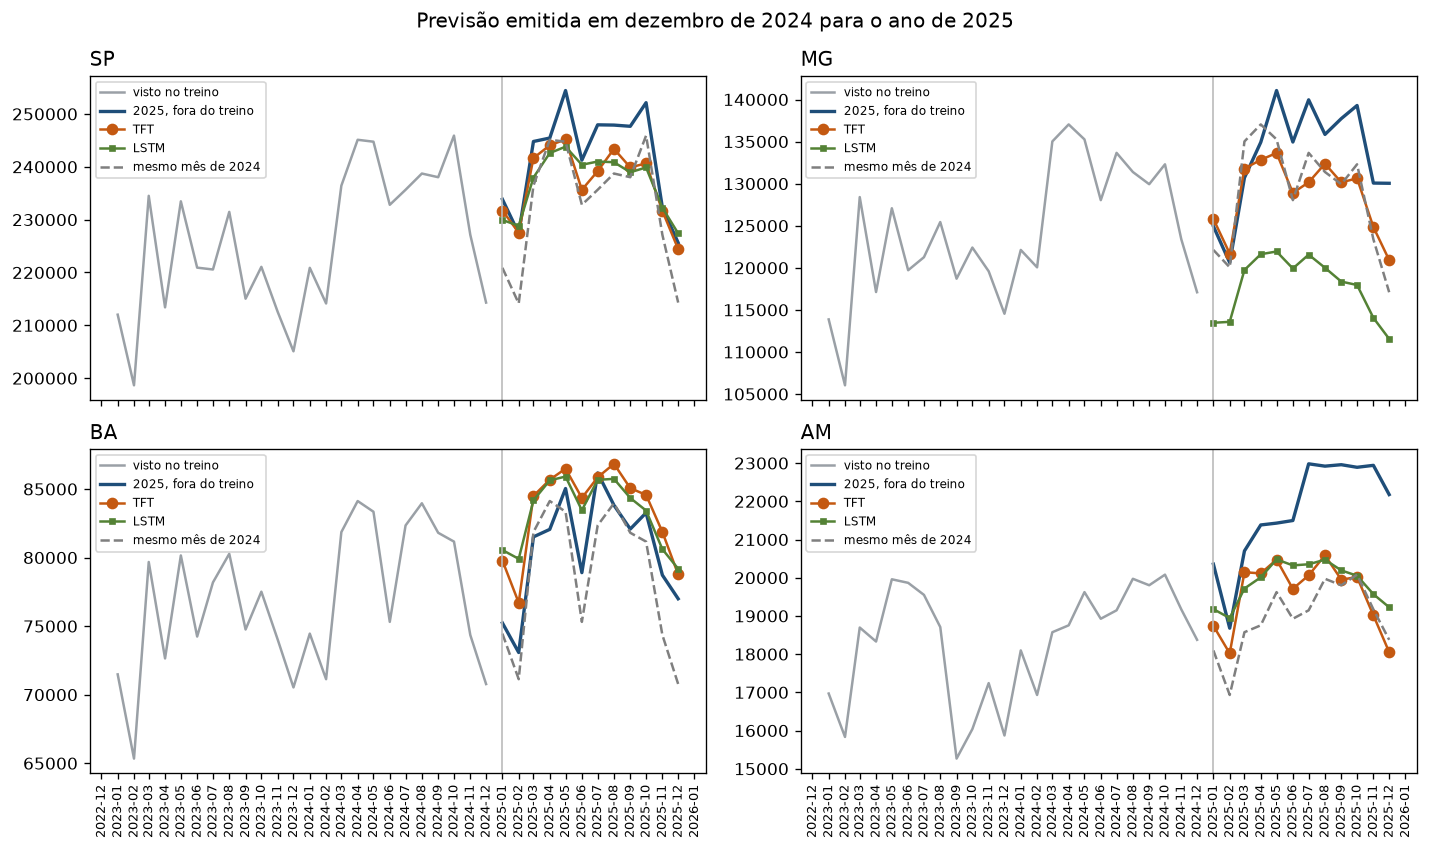

In [5]:
import matplotlib.dates as mdates

fig, eixos = plt.subplots(2, 2, figsize=(12, 7.2), sharex=True)
visto = painel.loc["2023-01-01":"2024-12-01"]
for eixo, uf in zip(eixos.ravel(), ["SP", "MG", "BA", "AM"]):
    eixo.plot(visto.index, visto[uf], color="#9aa0a6", label="visto no treino")
    eixo.plot(teste.index, teste[uf], color="#1f4e79", linewidth=2, label="2025, fora do treino")
    eixo.plot(tft.index, tft[uf], color="#c45911", marker="o", label="TFT")
    eixo.plot(lstm.index, lstm[uf], color="#548235", marker="s", markersize=3, label="LSTM")
    eixo.plot(
        referencia.index,
        referencia[uf],
        color="#7f7f7f",
        linestyle="--",
        label="mesmo mês de 2024",
    )
    eixo.axvline(pd.Timestamp("2025-01-01"), color="#bbbbbb", linewidth=1)
    eixo.set_title(uf, loc="left")
    eixo.legend(fontsize=7)
eixos[0, 0].xaxis.set_major_locator(mdates.MonthLocator())
eixos[0, 0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
for eixo in eixos.ravel():
    eixo.tick_params(axis="x", labelrotation=90, labelsize=8)
fig.suptitle("Previsão emitida em dezembro de 2024 para o ano de 2025")
fig.tight_layout()
fig.savefig(PASTA / "producao_2025.png", dpi=120, bbox_inches="tight")
plt.show()
